## Bài 4: Chẩn đoán mô hình, Phân tích lỗi, Trọng số đặc trưng và Thực hành tại chỗ

- So sánh kết quả Train vs CV Validation và vẽ **Đường cong học tập (`learning_curve`)** để nhận diện quá khớp / chưa khớp.
- **Phân tích lỗi :** So sánh trung vị và phân bố 4 nhóm `TP / TN / FP / FN` trên Tập Test.
- **Trọng số đặc trưng chuẩn hóa :** Đối chiếu 10 đặc trưng có trọng số mạnh nhất giữa `LogisticRegression` và `SGDClassifier`.

### 1. Thiết lập dữ liệu 70/15/15 và Khớp lại mô hình

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# Đồng bộ giao diện và bảng màu với Kiemtra1
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
PALETTE_4 = ["#2ecc71", "#3498db", "#e74c3c", "#f39c12"]

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_PATH = Path("../data/Loan_approval_data_2025.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/Loan_approval_data_2025.csv")
assert DATA_PATH.exists(), f"Không tìm thấy dữ liệu tại {DATA_PATH.resolve()}"

IMG_DIR = Path("../images")
MODEL_DIR = Path("../models")
IMG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)


def get_model_score(estimator, X_eval):
    '''Trích xuất điểm liên tục (xác suất lớp 1 hoặc khoảng cách decision_function).'''
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X_eval)[:, 1]
    return estimator.decision_function(X_eval)


def evaluate(y_true, y_pred, y_score):
    '''Tính bộ chỉ số đánh giá đa chiều cho bài toán phân loại tín dụng.'''
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "F1-Macro": f1_score(y_true, y_pred, average="macro"),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "PR-AUC": average_precision_score(y_true, y_score),
    }


def load_and_split_data():
    '''Nạp dữ liệu, loại bỏ customer_id và chia phân tầng 70% Train / 15% Val / 15% Test.'''
    df = pd.read_csv(DATA_PATH)
    X = df.drop(columns=["customer_id", "loan_status"])
    y = df["loan_status"]

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_SEED
    )

    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    num_cols = [c for c in X.columns if c not in cat_cols]
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            (
                "cat",
                OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"),
                cat_cols,
            ),
        ],
        remainder="drop",
    )
    return df, X, y, X_train, X_val, X_test, y_train, y_val, y_test, num_cols, cat_cols, preprocessor


def build_pipelines(preprocessor):
    '''Đóng gói mô hình cơ sở và các thuật toán Bài 4 & Bài 5 vào Pipeline thống nhất.'''
    models = {
        "Dummy (Baseline đa số)": DummyClassifier(strategy="most_frequent"),
        "Perceptron (PLA)": Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_SEED),
        "SGDClassifier (Log-loss + GD)": SGDClassifier(
            loss="log_loss",
            penalty="l2",
            alpha=1e-4,
            max_iter=1000,
            tol=1e-4,
            random_state=RANDOM_SEED,
        ),
        "Logistic Regression (Mặc định)": LogisticRegression(
            max_iter=1000, C=1.0, random_state=RANDOM_SEED
        ),
        "Logistic Regression (Balanced)": LogisticRegression(
            max_iter=1000, C=1.0, class_weight="balanced", random_state=RANDOM_SEED
        ),
    }
    return {
        name: Pipeline([("preprocessor", preprocessor), ("classifier", clf)])
        for name, clf in models.items()
    }

df, X, y, X_train, X_val, X_test, y_train, y_val, y_test, num_cols, cat_cols, preprocessor = load_and_split_data()
pipelines = build_pipelines(preprocessor)

fitted_pipelines = {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe

lr_pipe = fitted_pipelines["Logistic Regression (Mặc định)"]
sgd_pipe = fitted_pipelines["SGDClassifier (Log-loss + GD)"]
ohe_names = lr_pipe.named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(cat_cols).tolist()
feature_names = num_cols + ohe_names

print("Đã sẵn sàng dữ liệu và Pipeline cho bước chẩn đoán và phân tích lỗi.")

Đã sẵn sàng dữ liệu và Pipeline cho bước chẩn đoán và phân tích lỗi.


### 2. Chẩn đoán Quá khớp / Chưa khớp và Đường cong học tập (`learning_curve`)

BẢNG CHẨN ĐOÁN QUÁ KHỚP / CHƯA KHỚP (5-FOLD CV, N = 35.000)


,Mô hình,Train Acc,CV Val Acc,Chênh lệch Acc,Train AUC,CV Val AUC,Chênh lệch AUC
0,Dummy (Baseline đa số),0.5505,0.5505,0.0000,0.5000,0.5000,0.0000
1,Perceptron (PLA),0.8249,0.8248,0.0001,0.9138,0.9136,0.0001
2,SGDClassifier (Log-loss + GD),0.8662,0.8659,0.0003,0.9449,0.9448,0.0001
3,Logistic Regression (Mặc định),0.8671,0.8667,0.0004,0.9459,0.9457,0.0003
4,Logistic Regression (Balanced),0.8656,0.8651,0.0006,0.9459,0.9457,0.0003


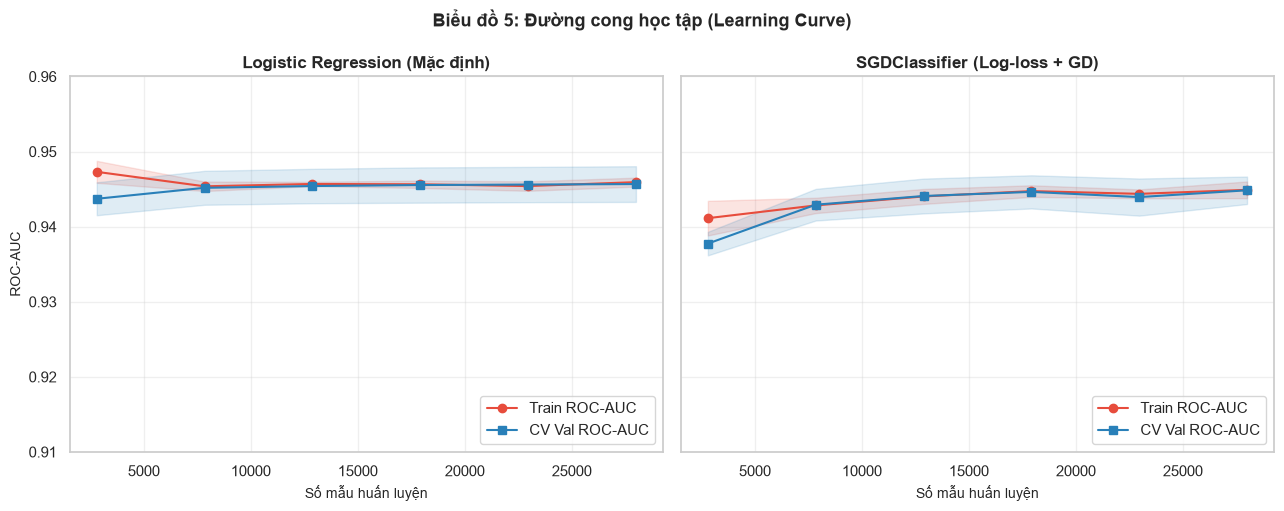

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
diag_rows = []
for name, pipe in pipelines.items():
    res = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "roc_auc"],
        return_train_score=True,
        n_jobs=-1,
    )
    diag_rows.append(
        {
            "Mô hình": name,
            "Train Acc": res["train_accuracy"].mean(),
            "CV Val Acc": res["test_accuracy"].mean(),
            "Chênh lệch Acc": res["train_accuracy"].mean() - res["test_accuracy"].mean(),
            "Train AUC": res["train_roc_auc"].mean(),
            "CV Val AUC": res["test_roc_auc"].mean(),
            "Chênh lệch AUC": res["train_roc_auc"].mean() - res["test_roc_auc"].mean(),
        }
    )

print("=" * 80)
print("BẢNG CHẨN ĐOÁN QUÁ KHỚP / CHƯA KHỚP (5-FOLD CV, N = 35.000)")
print("=" * 80)
display(pd.DataFrame(diag_rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
for ax, (title, pipe) in zip(
    axes,
    [
        ("Logistic Regression (Mặc định)", pipelines["Logistic Regression (Mặc định)"]),
        ("SGDClassifier (Log-loss + GD)", pipelines["SGDClassifier (Log-loss + GD)"]),
    ],
):
    sizes, tr_scores, va_scores = learning_curve(
        pipe, X_train, y_train, cv=cv, scoring="roc_auc", train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1
    )
    tr_m, tr_s = tr_scores.mean(axis=1), tr_scores.std(axis=1)
    va_m, va_s = va_scores.mean(axis=1), va_scores.std(axis=1)
    ax.plot(sizes, tr_m, "o-", color="#e74c3c", label="Train ROC-AUC")
    ax.fill_between(sizes, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color="#e74c3c")
    ax.plot(sizes, va_m, "s-", color="#2980b9", label="CV Val ROC-AUC")
    ax.fill_between(sizes, va_m - va_s, va_m + va_s, alpha=0.15, color="#2980b9")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Số mẫu huấn luyện")
    ax.set_ylim(0.91, 0.96)
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("ROC-AUC")
plt.suptitle("Biểu đồ 5: Đường cong học tập (Learning Curve)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(IMG_DIR / "duong_cong_hoc_tap_learning_curve.png", dpi=90)
plt.show()

- **Không bị quá khớp (Low Variance):** Ở cả `LogisticRegression` và `SGDClassifier`, độ lệch giữa Train và CV Val đều dưới `0,0005` (`< 0,05%`), hai đường cong hội tụ sát tại vùng `0,945 - 0,946`.
- **Trạng thái từng mô hình:** `Dummy` chưa khớp nặng (`AUC = 0,5000`); `Perceptron` chưa khớp ranh giới xác suất tốt bằng Log-loss; hai mô hình Log-loss đạt trạng thái khớp cân bằng tối ưu trong lớp siêu phẳng tuyến tính.

### 3. Phân tích lỗi (`Error Analysis`) tại vùng ranh giới quyết định trên Tập Test

TRUNG VỊ ĐẶC TRƯNG THEO 4 NHÓM KẾT QUẢ (LOGISTIC REGRESSION - TEST)


,credit_score,debt_to_income_ratio,interest_rate,annual_income,years_employed
Nhóm,,,,,
TP (Duyệt đúng),676.0,0.220,15.25,47072.5,7.10
TN (Từ chối đúng),597.0,0.351,15.70,36534.0,2.70
FP (Duyệt nhầm xấu),646.0,0.210,15.13,41658.0,4.80
FN (Từ chối nhầm tốt),624.0,0.322,14.50,41507.5,4.65


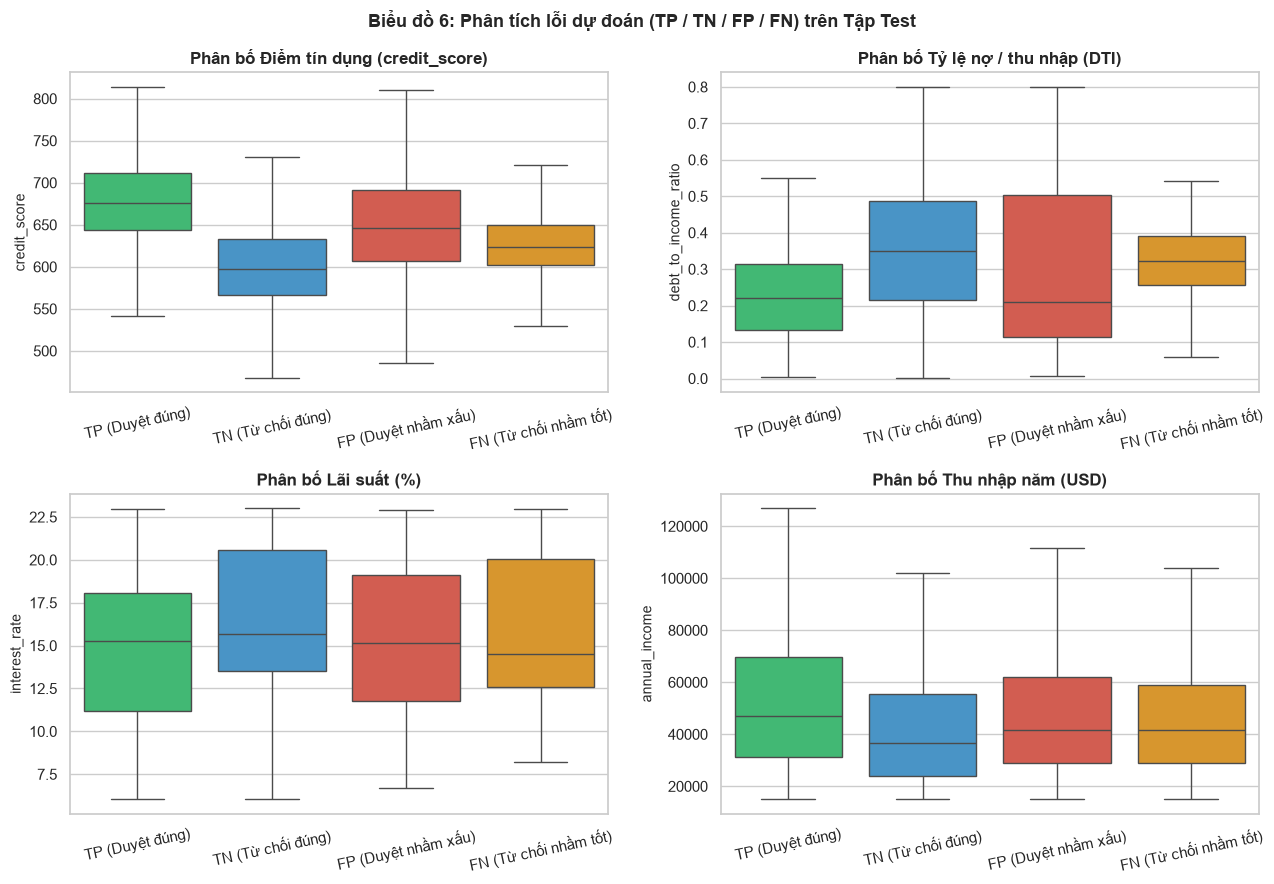

In [3]:
err_df = X_test.copy()
err_df["y_true"] = y_test.values
err_df["y_pred"] = lr_pipe.predict(X_test)


def classify_error_group(row):
    if row["y_true"] == 1 and row["y_pred"] == 1:
        return "TP (Duyệt đúng)"
    if row["y_true"] == 0 and row["y_pred"] == 0:
        return "TN (Từ chối đúng)"
    if row["y_true"] == 0 and row["y_pred"] == 1:
        return "FP (Duyệt nhầm xấu)"
    return "FN (Từ chối nhầm tốt)"


err_df["Nhóm"] = err_df.apply(classify_error_group, axis=1)

key_features = [
    ("credit_score", "Điểm tín dụng (credit_score)"),
    ("debt_to_income_ratio", "Tỷ lệ nợ / thu nhập (DTI)"),
    ("interest_rate", "Lãi suất (%)"),
    ("annual_income", "Thu nhập năm (USD)"),
]
group_order = [
    "TP (Duyệt đúng)",
    "TN (Từ chối đúng)",
    "FP (Duyệt nhầm xấu)",
    "FN (Từ chối nhầm tốt)",
]

median_cols = [c for c, _ in key_features] + ["years_employed"]
print("=" * 80)
print("TRUNG VỊ ĐẶC TRƯNG THEO 4 NHÓM KẾT QUẢ (LOGISTIC REGRESSION - TEST)")
print("=" * 80)
display(err_df.groupby("Nhóm")[median_cols].median().loc[group_order].round(3))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, title) in zip(axes.ravel(), key_features):
    sns.boxplot(
        data=err_df,
        x="Nhóm",
        y=col,
        hue="Nhóm",
        order=group_order,
        hue_order=group_order,
        palette=PALETTE_4,
        legend=False,
        showfliers=False,
        ax=ax,
    )
    ax.set_title(f"Phân bố {title}", fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=12)

plt.suptitle("Biểu đồ 6: Phân tích lỗi dự đoán (TP / TN / FP / FN) trên Tập Test", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(IMG_DIR / "phan_tich_loi_fp_fn.png", dpi=90)
plt.show()

- **Nhóm FP ($525$ ca -- duyệt nhầm nợ xấu):** Có chỉ số `debt_to_income_ratio` rất thấp (trung vị $0{,}210$, thấp hơn cả nhóm TP $0{,}220$) và thu nhập ổn ($41.658$ USD), khiến tổng tuyến tính vượt ngưỡng duyệt dù điểm tín dụng ở vùng cận biên ($646{,}0$).
- **Nhóm FN ($476$ ca -- từ chối nhầm khách tốt):** Có `debt_to_income_ratio` cao hơn hẳn ($0{,}322$) và điểm tín dụng thấp hơn ($624{,}0$) kéo xác suất xuống dưới $0{,}50$, dù lãi suất vay tương đối thấp (trung vị $14{,}50\%$).

### 4. So sánh trọng số đặc trưng chuẩn hóa (`coef_`) của Logistic Regression và SGDClassifier

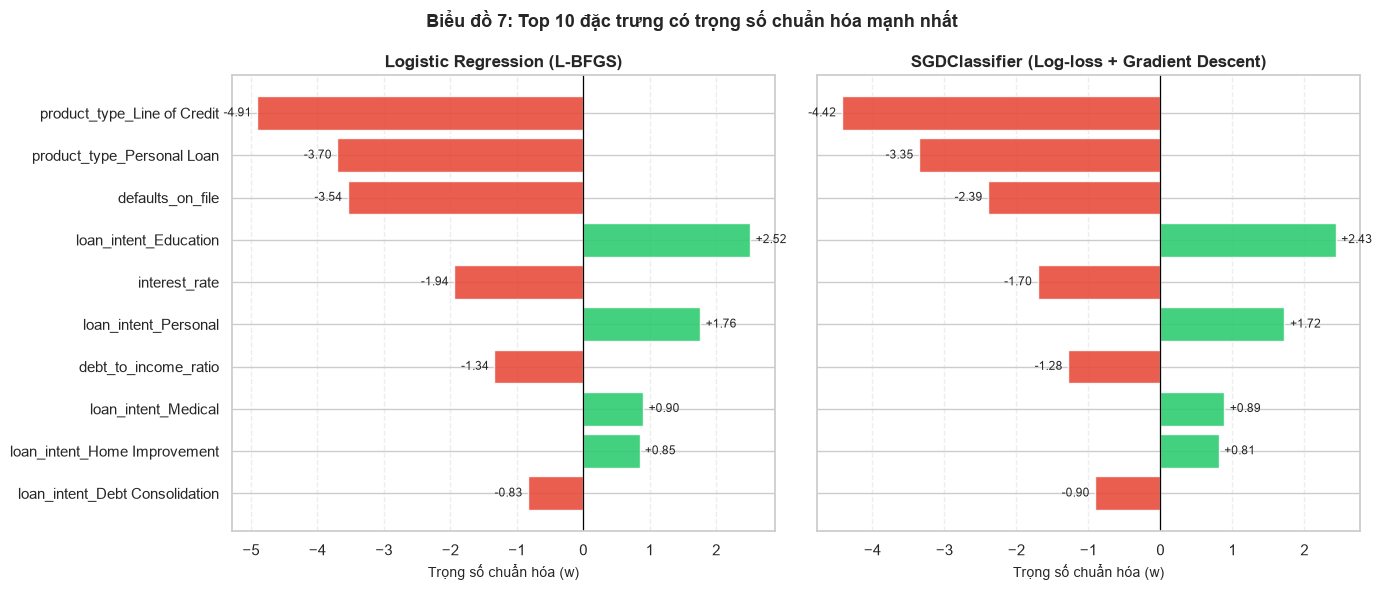

In [4]:
lr_coef = lr_pipe.named_steps["classifier"].coef_[0]
sgd_coef = sgd_pipe.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame(
    {
        "Đặc trưng": feature_names,
        "LogisticRegression (w)": lr_coef,
        "SGDClassifier (w)": sgd_coef,
        "|w| Logistic": np.abs(lr_coef),
    }
).sort_values("|w| Logistic", ascending=False)

top10 = coef_df.head(10).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, col_name, title in [
    (axes[0], "LogisticRegression (w)", "Logistic Regression (L-BFGS)"),
    (axes[1], "SGDClassifier (w)", "SGDClassifier (Log-loss + Gradient Descent)"),
]:
    vals = top10[col_name].values
    bar_colors = ["#2ecc71" if v >= 0 else "#e74c3c" for v in vals]
    bars = ax.barh(top10["Đặc trưng"], vals, color=bar_colors, alpha=0.9)
    ax.axvline(0, color="black", linewidth=0.9)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Trọng số chuẩn hóa (w)")
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    for bar, v in zip(bars, vals):
        offset = 0.08 if v >= 0 else -0.08
        ha = "left" if v >= 0 else "right"
        ax.text(v + offset, bar.get_y() + bar.get_height() / 2, f"{v:+.2f}", va="center", ha=ha, fontsize=8.5)

plt.suptitle("Biểu đồ 7: Top 10 đặc trưng có trọng số chuẩn hóa mạnh nhất", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(IMG_DIR / "do_quan_trong_dac_trung.png", dpi=90)
plt.show()

- **Nhóm trọng số âm mạnh ($w < 0$, đẩy về từ chối):** `product_type_Line of Credit` ($-4{,}91$), `product_type_Personal Loan` ($-3{,}70$), tiền sử vỡ nợ `defaults_on_file` ($-3{,}54$), lãi suất `interest_rate` ($-1{,}94$) và tỷ lệ nợ/thu nhập `debt_to_income_ratio` ($-1{,}34$).
- **Nhóm trọng số dương mạnh ($w > 0$, thúc đẩy duyệt):** Mục đích vay `loan_intent_Education` ($+2{,}52$), `loan_intent_Personal` ($+1{,}76$), lịch sử tín dụng `credit_history_years` ($+0{,}75$) và `credit_score`.